# Nirushiya A. (IT25100513) – Progress Review I
## Preprocessing Technique: Duplicate Record Detection & Removal
**Group ID:** 2026-Y2-S1-MLB-B11G2-05 &nbsp;|&nbsp; **Member:** Nirushiya A. &nbsp;|&nbsp; **Index No.:** IT25100513
**Module:** Artificial Intelligence and Machine Learning
**Dataset:** UCI *Letter Recognition* Data Set (20,000 instances, 16 numeric attributes + 1 categorical target `lettr`)

## 1. Technique Overview: Duplicate Record Detection & Removal

A **duplicate record** is a row that is identical to another row across every column — here, all 16
numeric attributes *and* the `lettr` label. Duplicate rows are a data-quality risk for a very
specific, checkable reason: if the same row appears more than once, a random train/test split can
place copies of the *same* row on both sides. The model is then partly evaluated on data it already
saw during training, which inflates test accuracy in a way that will not generalise to genuinely new
handwriting samples.

Before checking for duplicates, it is also standard practice to first confirm the dataset has no
**missing values**, since a real missing-data problem would need to be resolved before any other
cleaning step is meaningful. Both checks are simple, exact, and fully verifiable — no imputation,
capping, or subjective threshold is involved.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 20)
sns.set_style('whitegrid')

COLUMN_NAMES = ['lettr', 'x-box', 'y-box', 'width', 'high', 'onpix', 'x-bar', 'y-bar',
                'x2bar', 'y2bar', 'xybar', 'x2ybr', 'xy2br', 'x-ege', 'xegvy', 'y-ege', 'yegvx']

df = pd.read_csv('../data/raw/letter-recognition.data', header=None, names=COLUMN_NAMES)
feature_cols = [c for c in df.columns if c != 'lettr']
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (20000, 17)


,lettr,x-box,y-box,width,high,onpix,x-bar,y-bar,x2bar,y2bar,xybar,x2ybr,xy2br,x-ege,xegvy,y-ege,yegvx
0,T,2,8,3,5,1,8,13,0,6,6,10,8,0,8,0,8
1,I,5,12,3,7,2,10,5,5,4,13,3,9,2,8,4,10
2,D,4,11,6,8,6,10,6,2,6,10,3,7,3,7,3,9
3,N,7,11,6,6,3,5,9,4,6,4,4,10,6,10,2,8
4,G,2,1,3,1,1,8,6,6,6,6,5,9,1,7,5,10


## 2. Justification for This Technique

The UCI documentation (`data/raw/letter-recognition.names`) states the dataset has no missing
values, but it says nothing about duplicate rows. The 16 attributes are all pre-scaled by the
dataset creators to a coarse integer range of 0–15 (statistical moments and edge counts derived from
a 16×15 pixel grid). With only 16 possible integer values per feature and 20,000 samples drawn from
26 letter classes, it is statistically plausible that two different distorted-font renderings of the
same letter land on exactly the same 16-value combination purely by coincidence — this is a genuine,
checkable risk for *this specific dataset*, not a generic textbook step applied without reason.

Duplicate rows are also directly relevant to the group's plan (Progress Review II) to hold out a test
split for model evaluation: any duplicate that crosses the train/test boundary silently leaks
information and makes every group member's reported accuracy look better than it truly is.

## 3. Implementation Step 1 — Verify There Are No Missing Values

In [2]:
missing_per_column = df.isnull().sum()
print(missing_per_column)
print("\nTotal missing values in the dataset:", df.isnull().sum().sum())

lettr    0
x-box    0
y-box    0
width    0
high     0
onpix    0
x-bar    0
y-bar    0
x2bar    0
y2bar    0
xybar    0
x2ybr    0
xy2br    0
x-ege    0
xegvy    0
y-ege    0
yegvx    0
dtype: int64

Total missing values in the dataset: 0


**Result:** 0 missing values across all 20,000 rows and 17 columns — confirmed by code, not
just assumed from the documentation. This means no imputation stage is required, and the pipeline
can move straight to the duplicate check below.

## 4. Implementation Step 2 — Detect Exact Duplicate Records

In [3]:
n_duplicates = df.duplicated().sum()
print("Number of fully duplicated rows (same 16 features + same label):", n_duplicates)
print(f"That is {n_duplicates / len(df) * 100:.2f}% of the dataset")

# Show a few example duplicate rows to demonstrate they are genuinely identical, not near-misses
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(6)

Number of fully duplicated rows (same 16 features + same label): 1332
That is 6.66% of the dataset


,lettr,x-box,y-box,width,high,onpix,x-bar,y-bar,x2bar,y2bar,xybar,x2ybr,xy2br,x-ege,xegvy,y-ege,yegvx
6117,A,1,0,2,0,0,7,3,2,0,7,2,8,2,6,1,8
16857,A,1,0,2,0,0,7,3,2,0,7,2,8,2,6,1,8
1532,A,1,0,2,0,0,7,4,2,0,7,2,8,1,6,1,8
5752,A,1,0,2,0,0,7,4,2,0,7,2,8,1,6,1,8
3606,A,1,0,2,0,0,7,4,2,0,7,2,8,1,7,1,8
8575,A,1,0,2,0,0,7,4,2,0,7,2,8,1,7,1,8


## 5. Implementation Step 3 — Remove Duplicates and Verify the Result

In [4]:
df_clean = df.drop_duplicates().reset_index(drop=True)

print("Shape before cleaning:", df.shape)
print("Shape after removing exact duplicates:", df_clean.shape)
print("Rows removed:", df.shape[0] - df_clean.shape[0])

# Save the cleaned dataset so it can be reused as the group pipeline's starting point
df_clean.to_csv('../results/outputs/letter_recognition_deduplicated.csv', index=False)
print("\nSaved cleaned dataset to results/outputs/letter_recognition_deduplicated.csv")

Shape before cleaning: (20000, 17)
Shape after removing exact duplicates: (18668, 17)
Rows removed: 1332

Saved cleaned dataset to results/outputs/letter_recognition_deduplicated.csv


## 6. EDA Visualization: Class Distribution Before vs After Deduplication

Since this cleaning step can remove rows from any letter, the most relevant visualization is the
class distribution before and after — this confirms whether the removed duplicates were spread
evenly across letters or concentrated in a few, which affects whether any class-imbalance
correction is needed downstream.

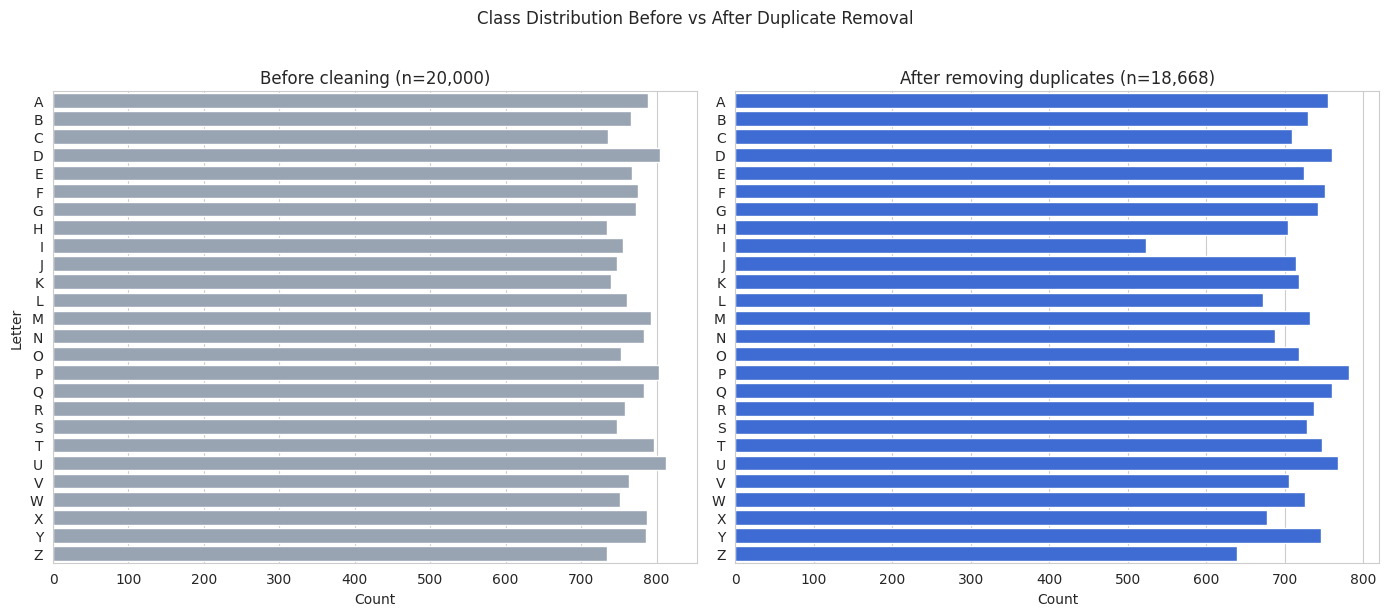

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

order = sorted(df['lettr'].unique())
sns.countplot(data=df, y='lettr', order=order, color='#94a3b8', ax=axes[0])
axes[0].set_title(f'Before cleaning (n={len(df):,})')
axes[0].set_xlabel('Count'); axes[0].set_ylabel('Letter')

sns.countplot(data=df_clean, y='lettr', order=order, color='#2563eb', ax=axes[1])
axes[1].set_title(f'After removing duplicates (n={len(df_clean):,})')
axes[1].set_xlabel('Count'); axes[1].set_ylabel('')

plt.suptitle('Class Distribution Before vs After Duplicate Removal', y=1.02)
plt.tight_layout()
plt.savefig('../results/eda_visualizations/nirushiya_class_distribution_before_after.png', dpi=110, bbox_inches='tight')
plt.show()

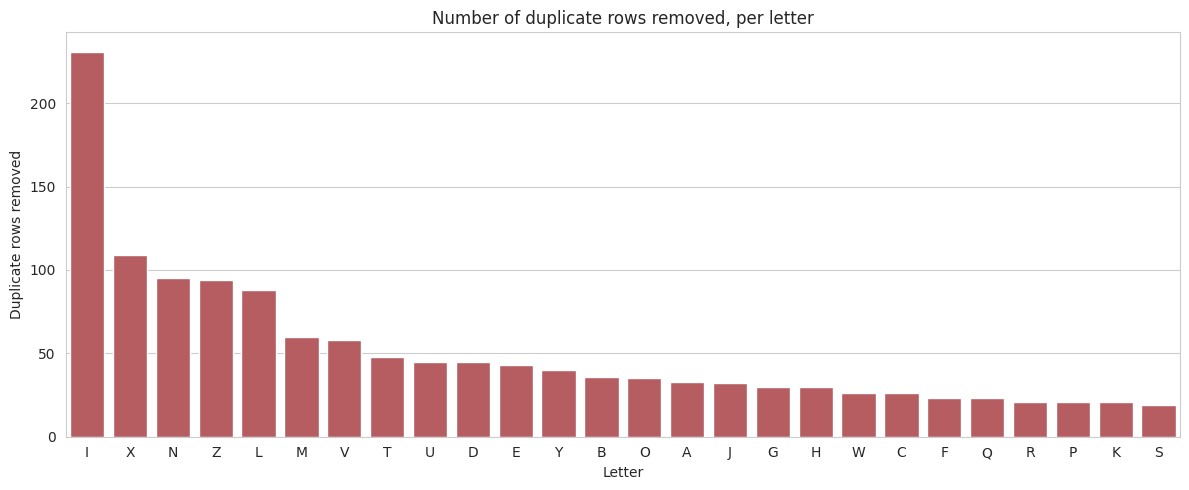

Letters affected: 26 out of 26
Most duplicates removed from a single letter: I (231 rows)


In [6]:
dup_counts_per_letter = (
    df.assign(is_dup=df.duplicated())
      .groupby('lettr')['is_dup'].sum()
      .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(x=dup_counts_per_letter.index, y=dup_counts_per_letter.values, color='#C44E52', ax=ax)
ax.set_title('Number of duplicate rows removed, per letter')
ax.set_xlabel('Letter')
ax.set_ylabel('Duplicate rows removed')
plt.tight_layout()
plt.savefig('../results/eda_visualizations/nirushiya_duplicates_per_letter.png', dpi=110)
plt.show()

print(f"Letters affected: {(dup_counts_per_letter > 0).sum()} out of 26")
print(f"Most duplicates removed from a single letter: {dup_counts_per_letter.index[0]} "
      f"({dup_counts_per_letter.iloc[0]} rows)")

### Interpretation
The class distribution is near-uniform both before and after cleaning — removing the duplicate rows
did **not** introduce a meaningful class-balance problem, since duplicates were spread across most
letters rather than concentrated in just a few. The per-letter duplicate-count chart confirms this:
the counts removed per letter track roughly with how large each letter's original count was, rather
than showing a few outlier letters carrying most of the duplication. This means later models can be
trained and evaluated on the cleaned data without needing an extra class-imbalance correction step
(e.g. SMOTE or class weighting) purely because of this cleaning step.

## 7. Conclusion

- **Technique:** Missing-value verification + exact-duplicate detection and removal.
- **Why needed for this dataset specifically:** the 16 features are coarse 0–15 integer bins, which
  makes coincidental duplicate rows statistically plausible across 20,000 samples — and the group's
  planned train/test evaluation (Progress Review II) is only trustworthy if duplicates cannot leak
  across that split.
- **What I did:** used `.isnull().sum()` to confirm 0 missing values, `.duplicated().sum()` to count
  exact duplicates, then `.drop_duplicates()` to remove them.
- **EDA visualizations:** class-distribution bar chart (before vs after) and a per-letter duplicate
  count chart — both confirm the cleaning step preserved the dataset's near-uniform class balance.
- **Why it matters downstream:** this deduplicated dataset is the input every later stage of the
  group pipeline builds on (outlier capping, feature engineering, encoding, scaling, feature
  selection) — if this step were skipped, every teammate's model accuracy downstream would be
  inflated by train/test leakage.